# Week 9 – Naive result and failure argument
Project 3: *Decomposing the Biological Prior*. This notebook reads `results/week9/runs.jsonl` (the finished runs) and rebuilds every number used in the report and the slides. Nothing is re-trained here.

**Setup:** random binary patterns (d=50), P patterns, n noisy training copies per pattern, test on fresh noisy copies. Conditions: `masked_sign` (real mask + real signs, clipped after each step) vs `dense_params` (parameter-matched dense net). 3 seeds, n in {1,3,10}. Metric: test accuracy (1.0 perfect, about 0.5 chance).

In [1]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
rows=[json.loads(l) for l in open('results/week9/runs.jsonl')]
df=pd.DataFrame(rows)
print(len(df),'rows')
# the extra P=40, n=30 row is a timing run, not part of the grid
allruns=df.copy()   # everything, incl. the sign-free control and seeds 3-4
# main grid: the two naive conditions, seeds 0-2, n in {1,3,10}
df=df[df.n.isin([1,3,10])&df.condition.isin(['masked_sign','dense_params'])&(df.seed<3)].copy()
print(len(df),'grid rows')
df.groupby(['dataset','condition']).size()

253 rows
216 grid rows


dataset  condition   
fafb     dense_params    54
         masked_sign     54
malecns  dense_params    54
         masked_sign     54
dtype: int64

## 1. Accuracy tables (n = 10, mean over 3 seeds)

In [2]:
for ds in ['fafb','malecns']:
    t=df[(df.dataset==ds)&(df.n==10)].pivot_table(index='P',columns='condition',values='test_acc',aggfunc='mean').round(3)
    sd=df[(df.dataset==ds)&(df.n==10)].pivot_table(index='P',columns='condition',values='test_acc',aggfunc='std').round(3).add_suffix('_sd')
    print(ds); display(pd.concat([t,sd],axis=1))

fafb


condition,dense_params,masked_sign,dense_params_sd,masked_sign_sd
P,,,,
10,0.986,0.992,0.005,0.001
20,0.936,0.946,0.031,0.022
40,0.956,0.932,0.008,0.010
80,0.942,0.920,0.010,0.012
160,0.927,0.927,0.005,0.006
320,0.880,0.839,0.014,0.036


malecns


condition,dense_params,masked_sign,dense_params_sd,masked_sign_sd
P,,,,
10,0.988,0.992,0.004,0.002
20,0.944,0.944,0.015,0.022
40,0.956,0.902,0.015,0.031
80,0.947,0.904,0.011,0.018
160,0.936,0.927,0.013,0.002
320,0.891,0.888,0.013,0.009


## 2. Effect of n (mean over P and seeds)

In [3]:
display(df.pivot_table(index=['dataset','n'],columns='condition',values='test_acc',aggfunc='mean').round(3))

condition   dense_params  masked_sign
dataset n                            
fafb    1          0.655        0.766
        3          0.810        0.813
        10         0.938        0.926
malecns 1          0.674        0.759
        3          0.838        0.815
        10         0.944        0.926

## 3. Problem 1: dense runs that stop near chance
A run counts as collapsed if test accuracy is within 0.05 of the majority baseline.

In [4]:
df['collapsed']=(df.test_acc-df.majority_test_acc)<0.05
display(df.groupby(['dataset','condition']).collapsed.agg(['sum','count']))
print(df[df.condition=='dense_params'].groupby('n').collapsed.sum())

sum  count
dataset condition               
fafb    dense_params    7     54
        masked_sign     0     54
malecns dense_params    5     54
        masked_sign     0     54

n
1     10
3      2
10     0
Name: collapsed, dtype: int64


## 4. Problems 2 and 3: clipping

In [5]:
m=df[df.condition=='masked_sign']
print('clipped share per step (violation_mean):')
display(m.groupby('dataset').violation_mean.mean().round(3))
m=m.assign(nz=m.effective_nonzero/m.mask_weights)
print('share of mask weights still nonzero after training:')
display(m.groupby('dataset').nz.mean().round(3))

clipped share per step (violation_mean):


dataset
fafb       0.130
malecns    0.154
Name: violation_mean, dtype: float64

share of mask weights still nonzero after training:


dataset
fafb       0.851
malecns    0.859
Name: nz, dtype: float64

## 5. Training loss, masked vs dense (paired by dataset, seed, P, n)

In [6]:
p=df.pivot_table(index=['dataset','seed','P','n'],columns='condition',values='train_loss')
p['diff']=p.masked_sign-p.dense_params
print('share of runs where masked has lower train loss:'); display((p['diff']<0).groupby('dataset').mean().round(2))
display(p['diff'].groupby('dataset').median().round(4))

share of runs where masked has lower train loss:


dataset
fafb       0.57
malecns    0.54
Name: diff, dtype: float64

dataset
fafb      -0.0060
malecns   -0.0037
Name: diff, dtype: float64

## 6. Ablation of 30% of units (P=80)

In [7]:
a=df[(df.P==80)&df.ablation_test_acc.apply(lambda x:isinstance(x,dict))].copy()
a['abl30']=a.ablation_test_acc.apply(lambda d:d['0.3'])
display(a.pivot_table(index='dataset',columns='condition',values='abl30',aggfunc='mean').round(3))

condition,dense_params,masked_sign
dataset,,
fafb,0.660,0.710
malecns,0.688,0.608


## 7. Figure: accuracy vs P

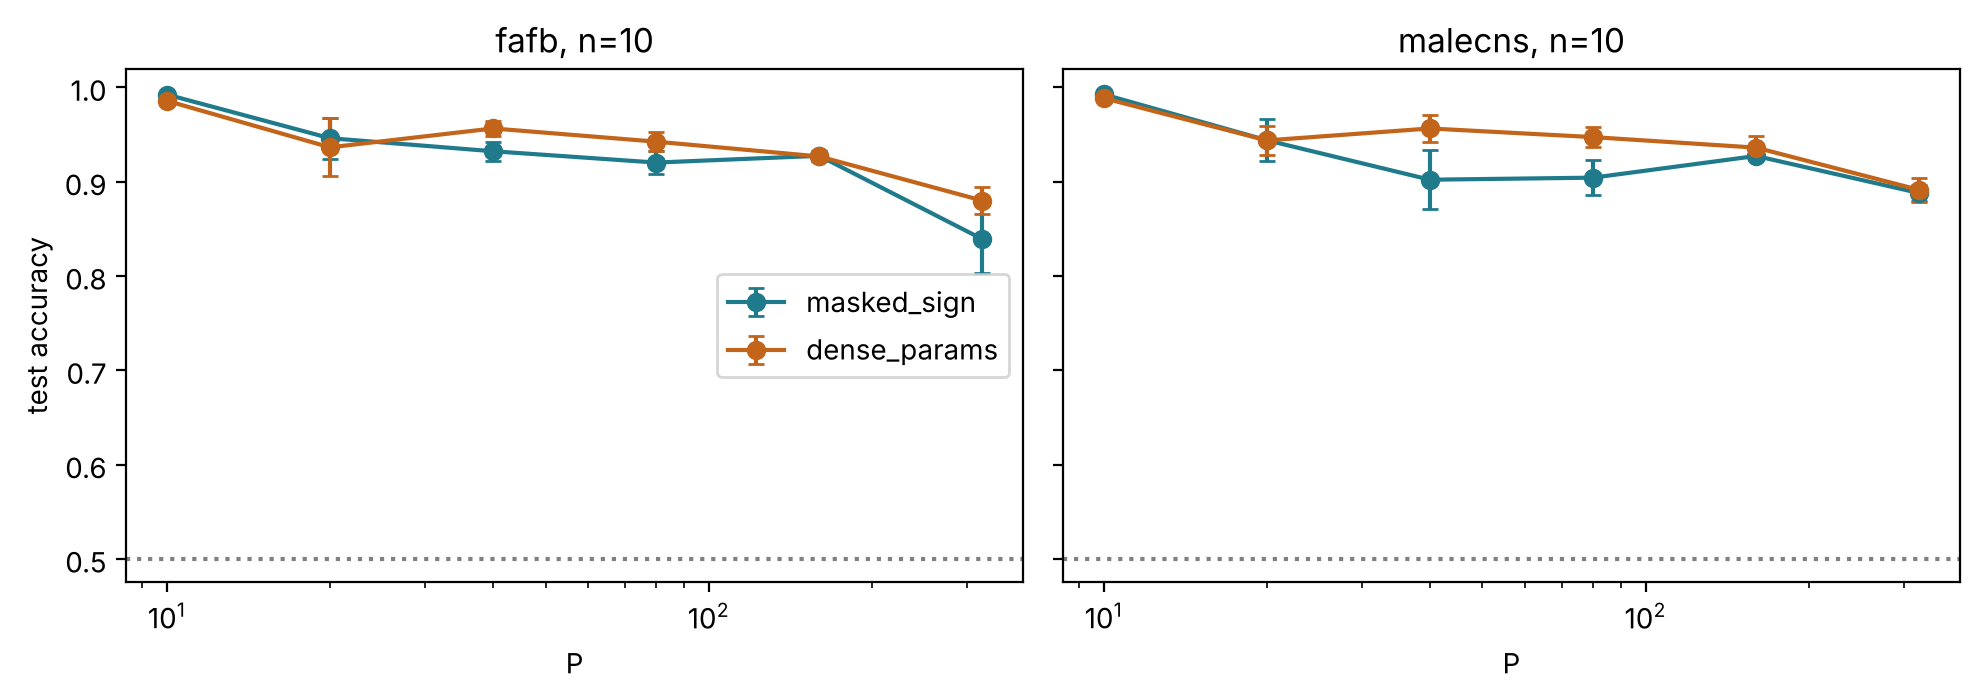

In [8]:
fig,ax=plt.subplots(1,2,figsize=(10,3.6),sharey=True)
for a_,ds in zip(ax,['fafb','malecns']):
    for c,col in [('masked_sign','#1F7A8C'),('dense_params','#C2641A')]:
        s=df[(df.dataset==ds)&(df.n==10)&(df.condition==c)].groupby('P').test_acc
        a_.errorbar(s.mean().index,s.mean().values,yerr=s.std().values,label=c,color=col,marker='o',capsize=3)
    a_.set_xscale('log');a_.set_title(ds+', n=10');a_.set_xlabel('P');a_.axhline(0.5,ls=':',c='grey')
ax[0].set_ylabel('test accuracy');ax[0].legend();plt.tight_layout();plt.show()

## 8. Sign-free control (added 23 November)
Same true mask without the sign constraint (`masked_free`). n = 10, P = 40 and 80, seeds 0-4 for all three conditions.

In [9]:
c=allruns[(allruns.n==10)&allruns.P.isin([40,80])&(allruns.seed<5)]
t=c.pivot_table(index=['dataset','P'],columns='condition',values='test_acc',aggfunc=['mean','std']).round(3)
display(t)
print(c.groupby(['dataset','P','condition']).size().unstack().iloc[0].to_dict(),'seeds per cell (first row)')

mean                                  std              \
condition  dense_params masked_free masked_sign dense_params masked_free   
dataset P                                                                  
fafb    40        0.957       0.942       0.932        0.007       0.005   
        80        0.944       0.921       0.919        0.008       0.008   
malecns 40        0.958       0.932       0.917        0.011       0.035   
        80        0.948       0.947       0.900        0.009       0.018   

                        
condition  masked_sign  
dataset P               
fafb    40       0.007  
        80       0.010  
malecns 40       0.031  
        80       0.027

{'dense_params': 5, 'masked_free': 5, 'masked_sign': 5} seeds per cell (first row)


In [10]:
# training loss: signed minus unsigned, paired by seed (derivation: signed cannot be lower with an exact solver)
p=c.pivot_table(index=['dataset','seed','P'],columns='condition',values='train_loss')
p['d']=p.masked_sign-p.masked_free
display(pd.DataFrame({'signed_lower':(p.d<0).groupby('dataset').sum(),'pairs':p.d.groupby('dataset').size(),'median_diff':p.d.groupby('dataset').median().round(4)}))

,signed_lower,pairs,median_diff
dataset,,,
fafb,0,10,0.0111
malecns,2,10,0.0283


## Reading
Small P: equal. P=40 and 80: dense slightly ahead, within seed spread. No clear winner with 3 seeds. The dense control fails to train in some n=1 runs, and clipping removes a visible share of masked weights, so this naive contrast cannot separate sign, structure, degree and sparsity (see report, failure argument).

Sign-free control: FlyWire unchanged and dense still ahead; male CNS gap closes at P=80 but seed spread is large. **Not done yet:** n = 30, 100; equal-unit dense control; measuring rho and learning curves.